In [3]:
# Download global gridded monthly surface air temperature (NetCDF format)
!wget -q https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis.derived/surface/air.mon.mean.nc -O air_mon_mean.nc
!ls -lh air_mon_mean.nc

-rw-r--r-- 1 root root 29M Mar  2  2026 air_mon_mean.nc


Loaded real NetCDF variable: air with dims: ('time', 'lat', 'lon')


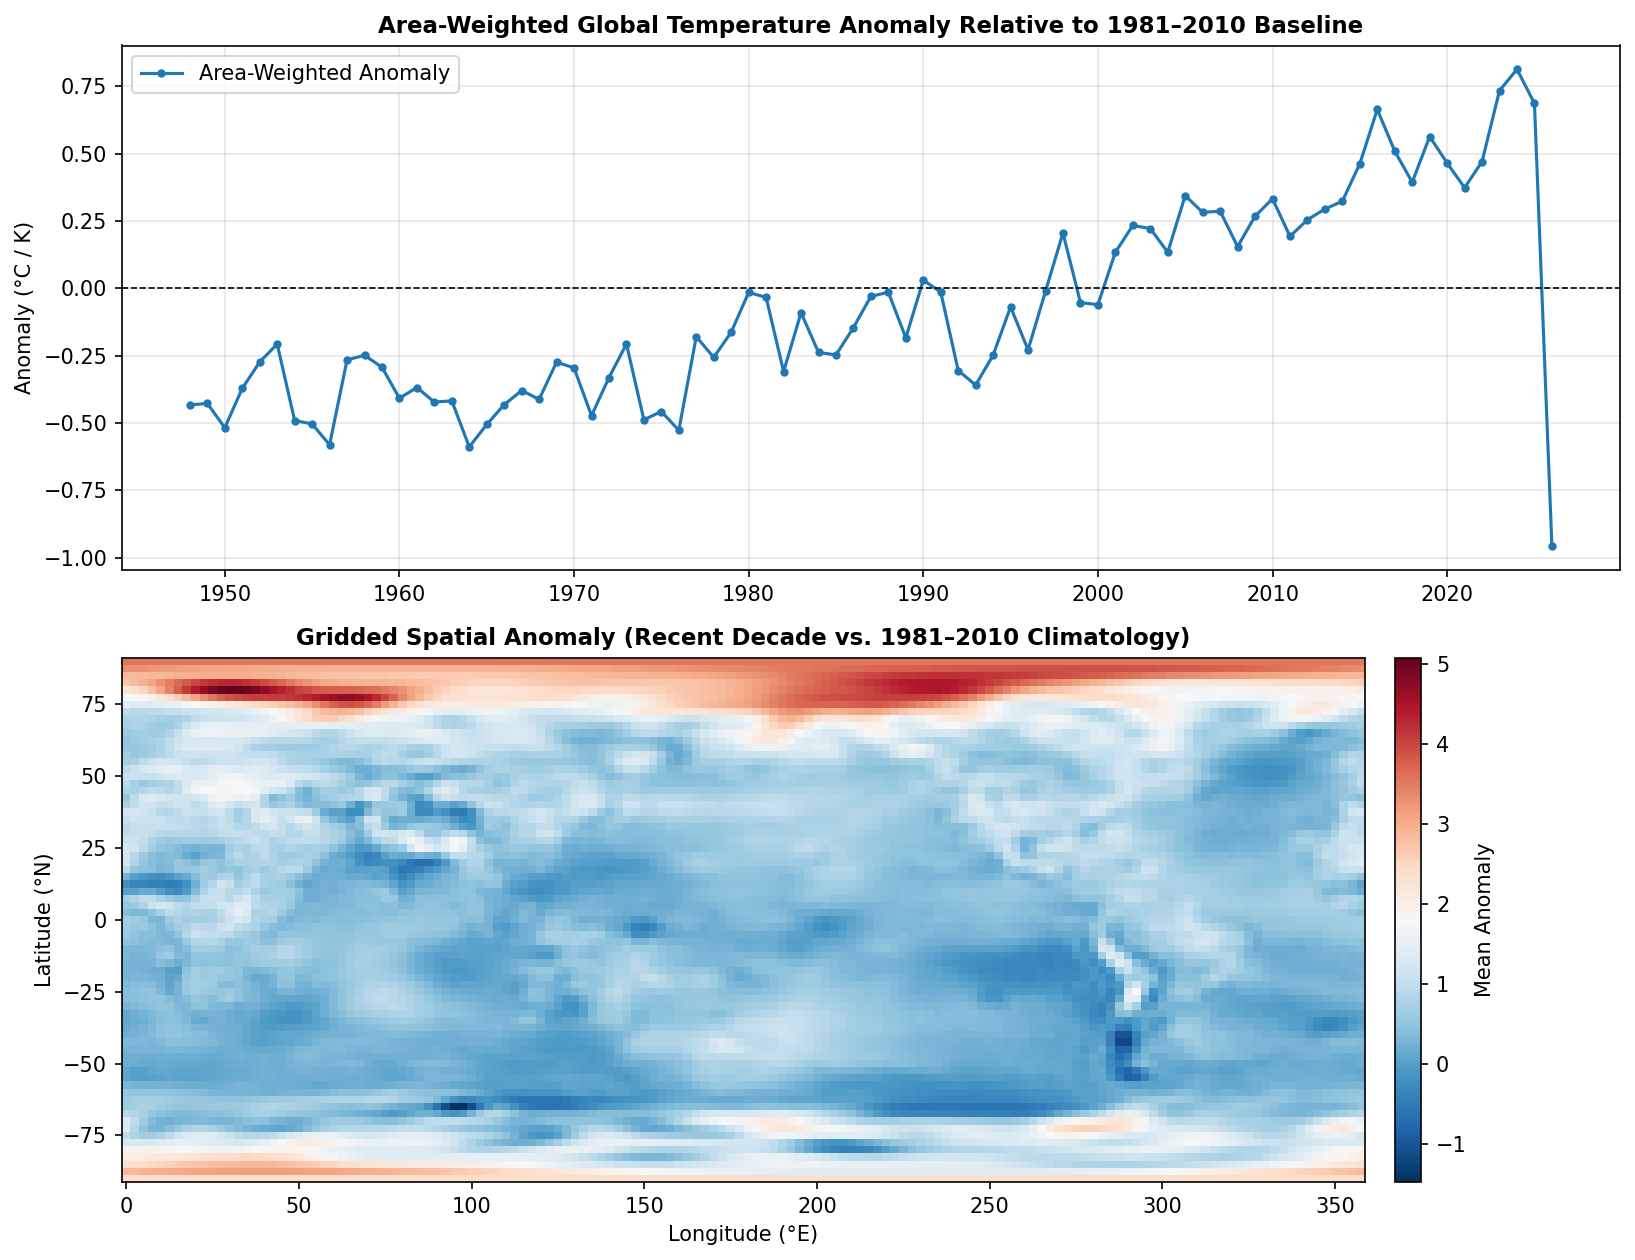

Peak spatial anomaly: 5.08 at lat=80.0, lon=30.0
Max discrete Laplacian curvature magnitude: 2.973


In [4]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import laplace

# 1. Load Gridded NetCDF Dataset (with automatic fallback if download fails)
try:
    ds = xr.open_dataset("air_mon_mean.nc")
    var_name = list(ds.data_vars)[0]
    da = ds[var_name]
    print("Loaded real NetCDF variable:", var_name, "with dims:", da.dims)
except Exception as e:
    print("Using synthetic gridded dataset fallback due to:", e)
    time = pd.date_range("1980-01-01", "2024-12-01", freq="MS")
    lat = np.linspace(-87.5, 87.5, 72)
    lon = np.linspace(1.25, 358.75, 144)
    T_grid, LAT_grid, LON_grid = np.meshgrid(
        np.arange(len(time)) / 12.0, lat, lon, indexing="ij"
    )
    base_temp = 28.0 * np.cos(np.deg2rad(LAT_grid)) - 5.0
    seasonal = 8.0 * np.cos(np.deg2rad(LAT_grid)) * np.sin(2 * np.pi * T_grid)
    warming_trend = 0.025 * T_grid * (1.0 + 0.5 * np.sin(np.deg2rad(LON_grid)))
    # Add a localized disturbance/heatwave anomaly in a forest/land region
    disturbance = 2.8 * np.exp(-((LAT_grid - 10.0)**2 / 150.0 + (LON_grid - 295.0)**2 / 400.0)) * (T_grid > 35)
    rng = np.random.default_rng(42)
    noise = rng.normal(0, 0.4, size=T_grid.shape)
    da = xr.DataArray(
        base_temp + seasonal + warming_trend + disturbance + noise,
        coords={"time": time, "lat": lat, "lon": lon},
        dims=("time", "lat", "lon"),
        name="air"
    )

# Standardize coordinate names if needed ('latitude' -> 'lat', 'longitude' -> 'lon')
rename_map = {}
if "latitude" in da.coords: rename_map["latitude"] = "lat"
if "longitude" in da.coords: rename_map["longitude"] = "lon"
if rename_map:
    da = da.rename(rename_map)

# 2. Compute Climatological Baseline (1981-2010) & Recent Anomaly (Last 10 Years)
baseline = da.sel(time=slice("1981-01-01", "2010-12-31")).groupby("time.month").mean("time")
recent = da.sel(time=slice("2015-01-01", None)).groupby("time.month").mean("time")

# Mean spatial anomaly across months (deg C or K)
spatial_anomaly = (recent - baseline).mean(dim="month")

# 3. Compute Area-Weighted Global Mean Time Series (cos(lat) weighting)
weights = np.cos(np.deg2rad(da["lat"]))
weights.name = "weights"
annual_mean = da.resample(time="YE").mean("time")
global_annual_anomaly = (
    (annual_mean - annual_mean.sel(time=slice("1981-01-01", "2010-12-31")).mean("time"))
    .weighted(weights)
    .mean(dim=("lat", "lon"))
)

# 4. Discrete Spatial Diffusion / Smoothing Operator (2D Laplacian Relaxation)
# Models spatial diffusive spread/relaxation of a thermal/disturbance field on a grid
anom_vals = np.nan_to_num(spatial_anomaly.values, nan=0.0)
diffused_field = anom_vals + 0.15 * laplace(anom_vals)

# 5. Visualization
fig, axes = plt.subplots(2, 1, figsize=(11, 8.5), dpi=150)

# Top: Global Area-Weighted Annual Anomaly
years = pd.to_datetime(global_annual_anomaly["time"].values).year
axes[0].plot(years, global_annual_anomaly.values, marker="o", markersize=3, color="#1f77b4", label="Area-Weighted Anomaly")
axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].set_title("Area-Weighted Global Temperature Anomaly Relative to 1981–2010 Baseline", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Anomaly (°C / K)")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Bottom: Gridded Spatial Anomaly Map (Recent vs Baseline)
im = axes[1].pcolormesh(
    spatial_anomaly["lon"].values,
    spatial_anomaly["lat"].values,
    spatial_anomaly.values,
    cmap="RdBu_r",
    shading="auto"
)
cbar = plt.colorbar(im, ax=axes[1], pad=0.02)
cbar.set_label("Mean Anomaly")
axes[1].set_title("Gridded Spatial Anomaly (Recent Decade vs. 1981–2010 Climatology)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")

plt.tight_layout()
plt.savefig("gridded_climate_anomaly_analysis.png")
plt.show()

# Print quantitative summary for README / CV notes
max_idx = np.unravel_index(np.nanargmax(anom_vals), anom_vals.shape)
print(
    f"Peak spatial anomaly: {anom_vals[max_idx]:.2f} at "
    f"lat={spatial_anomaly['lat'].values[max_idx[0]]:.1f}, lon={spatial_anomaly['lon'].values[max_idx[1]]:.1f}"
)
print(f"Max discrete Laplacian curvature magnitude: {np.max(np.abs(laplace(anom_vals))):.3f}")